In [1]:
import os # Configure which GPU

if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Import Sionna
try:
    import sionna
except ImportError as e:
    # Install Sionna if package is not already installed
    import os
    os.system("pip install sionna")
    import sionna

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

# Colab does currently not support the latest version of ipython.
# Thus, the preview does not work in Colab. However, whenever possible we
# strongly recommend to use the scene preview mode.
try: # detect if the notebook runs in Colab
    import google.colab
    no_preview = True # deactivate preview
except:
    if os.getenv("SIONNA_NO_PREVIEW"):
        no_preview = True
    else:
        no_preview = False

resolution = [480,320] # increase for higher quality of renderings

# Define magic cell command to skip a cell if needed
from IPython.core.magic import register_cell_magic
from IPython import get_ipython

@register_cell_magic
def skip_if(line, cell):
    if eval(line):
        return
    get_ipython().run_cell(cell)



In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import time
import pandas as pd

# Set random seed for reproducibility

# Import Sionna RT components
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera, Paths

# For link-level simulations
from sionna.channel import cir_to_ofdm_channel, subcarrier_frequencies, OFDMChannel, ApplyOFDMChannel, CIRDataset
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.utils import compute_ber, ebnodb2no, PlotBER

from nr_pusch.model import Model, CIRGenerator, PUSCHModel
from nr_pusch.configs import SISOConfig, MIMOConfig

sionna.config.seed = 42
tf.random.set_seed(42)
np.random.seed(42)
    


In [3]:
# Load integrated scene
scene = load_scene(sionna.rt.scene.munich) # Try also sionna.rt.scene.etoile

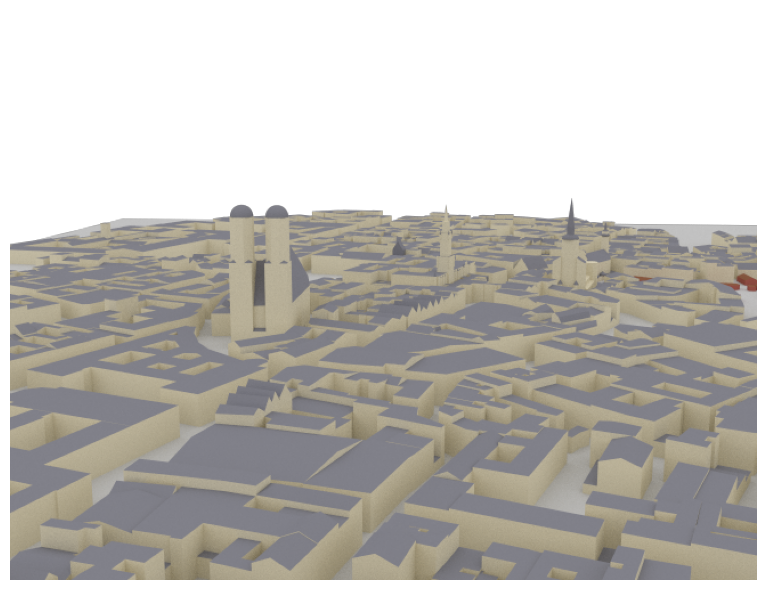

In [4]:
# Render scene
if no_preview:
    scene.render(camera="scene-cam-0", num_samples=512);

# The preview camera can be directly rendered as high-quality image (option only available in local mode)
if not no_preview:
    scene.preview()
    scene.render(camera="preview", num_samples=512);
else:
    print("Function not available in Colab mode.")

In [5]:
# %%skip_if no_preview
# # Open 3D preview (only works in Jupyter notebook)
# scene.preview()

One can also render the image to a file as shown below:

In [6]:
render_to_file = False # Set to True to render image to file

# Render scene to file from preview viewpoint
if render_to_file:
    scene.render_to_file(camera="scene-cam-0", # Also try camera="preview"
                         filename="scene.png",
                         resolution=[650,500])

Instead of the preview camera, one can also specify dedicated cameras with different positions and `look_at` directions.

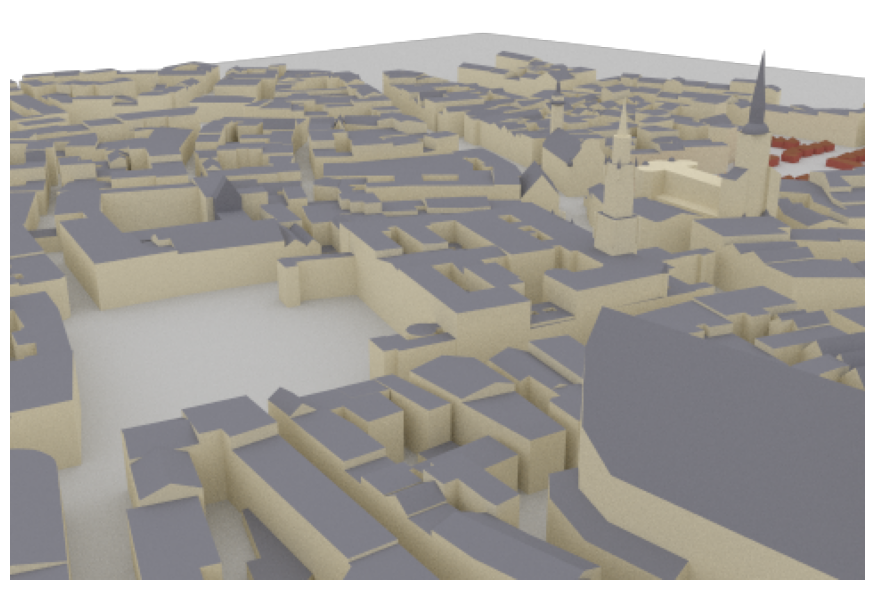

In [7]:
# Create new camera with different configuration
my_cam = Camera("my_cam", position=[-250,250,150], look_at=[-15,30,28])
scene.add(my_cam)

# Render scene with new camera*
scene.render("my_cam", resolution=resolution, num_samples=512); # Increase num_samples to increase image quality

In [8]:
# Configure antenna array for all transmitters
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

# Configure antenna array for all receivers
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="dipole",
                             polarization="cross")

# Create transmitter
tx = Transmitter(name="tx",
                 position=[8.5,21,27])

# Add transmitter instance to scene
scene.add(tx)

# Create a receiver
rx = Receiver(name="rx",
              position=[45,90,1.5],
              orientation=[0,0,0])

# Add receiver instance to scene
scene.add(rx)

tx.look_at(rx) # Transmitter points towards receiver

In [9]:
scene.frequency = 2.14e9 # in Hz; implicitly updates RadioMaterials

scene.synthetic_array = True # If set to False, ray tracing will be done per antenna element (slower for large arrays)

The default scenes have RadioMaterials assigned to each scene object. However, the RadioMaterial of a specific object can be modified and customized by the user.

In [10]:
# Select an example object from the scene
so = scene.get("Altes_Rathaus-itu_marble")

# Print name of assigned radio material for different frequenies
for f in [3.5e9, 2.14e9]: # Print for differrent frequencies
    scene.frequency = f
    print(f"\nRadioMaterial: {so.radio_material.name} @ {scene.frequency/1e9:.2f}GHz")
    print("Conductivity:", so.radio_material.conductivity.numpy())
    print("Relative permittivity:", so.radio_material.relative_permittivity.numpy())
    print("Complex relative permittivity:", so.radio_material.complex_relative_permittivity.numpy())
    print("Relative permeability:", so.radio_material.relative_permeability.numpy())
    print("Scattering coefficient:", so.radio_material.scattering_coefficient.numpy())
    print("XPD coefficient:", so.radio_material.xpd_coefficient.numpy())


RadioMaterial: itu_marble @ 3.50GHz
Conductivity: 0.017550057
Relative permittivity: 7.074
Complex relative permittivity: (7.074-0.090132594j)
Relative permeability: 1.0
Scattering coefficient: 0.0
XPD coefficient: 0.0

RadioMaterial: itu_marble @ 2.14GHz
Conductivity: 0.0111273555
Relative permittivity: 7.074
Complex relative permittivity: (7.074-0.09346512j)
Relative permeability: 1.0
Scattering coefficient: 0.0
XPD coefficient: 0.0


In [11]:
# Compute propagation paths
paths = scene.compute_paths(max_depth=5,
                            num_samples=5e4)  # Number of rays shot into directions defined
                                              # by a Fibonacci sphere , too few rays can
                                              # lead to missing paths

# Visualize paths in the scene
if no_preview:
    scene.render("my_cam", paths=paths, show_devices=True, show_paths=True, resolution=resolution);

In [12]:
# %%skip_if no_preview
# scene.preview(paths, show_devices=True, show_paths=True) # Use the mouse to focus on the visualized paths

In [13]:
# Show the coordinates of the starting points of all rays.
# These coincide with the location of the transmitters.
print("Source coordinates: ", paths.sources.numpy())
print("Transmitter coordinates: ", list(scene.transmitters.values())[0].position.numpy())

# Show the coordinates of the endpoints of all rays.
# These coincide with the location of the receivers.
print("Target coordinates: ",paths.targets.numpy())
print("Receiver coordinates: ",list(scene.receivers.values())[0].position.numpy())

# Show the types of all paths:
# 0 - LoS, 1 - Reflected, 2 - Diffracted, 3 - Scattered
# Note that Diffraction and scattering are turned off by default.
print("Path types: ", paths.types.numpy())

Source coordinates:  [[ 8.5 21.  27. ]]
Transmitter coordinates:  [ 8.5 21.  27. ]
Target coordinates:  [[45.  90.   1.5]]
Receiver coordinates:  [45.  90.   1.5]
Path types:  [[0 1 1 1 1 1 1 1 1 1 1 1]]


In [14]:
# We can now access for every path the channel coefficient, the propagation delay,
# as well as the angles of departure and arrival, respectively (zenith and azimuth).

# Let us inspect a specific path in detail
path_idx = 4 # Try out other values in the range [0, 13]

# For a detailed overview of the dimensions of all properties, have a look at the API documentation
print(f"\n--- Detailed results for path {path_idx} ---")
print(f"Channel coefficient: {paths.a[0,0,0,0,0,path_idx, 0].numpy()}")
print(f"Propagation delay: {paths.tau[0,0,0,path_idx].numpy()*1e6:.5f} us")
print(f"Zenith angle of departure: {paths.theta_t[0,0,0,path_idx]:.4f} rad")
print(f"Azimuth angle of departure: {paths.phi_t[0,0,0,path_idx]:.4f} rad")
print(f"Zenith angle of arrival: {paths.theta_r[0,0,0,path_idx]:.4f} rad")
print(f"Azimuth angle of arrival: {paths.phi_r[0,0,0,path_idx]:.4f} rad")


--- Detailed results for path 4 ---
Channel coefficient: (-9.85727001534542e-06-1.182470086291687e-07j)
Propagation delay: 0.75675 us
Zenith angle of departure: 1.6632 rad
Azimuth angle of departure: 1.2045 rad
Zenith angle of arrival: 1.6632 rad
Azimuth angle of arrival: -1.9260 rad


In [15]:
# Default parameters in the PUSCHConfig
subcarrier_spacing = 15e3
fft_size = 48

Doppler Effect

In [16]:
# Print shape of channel coefficients before the application of Doppler shifts
# The last dimension corresponds to the number of time steps which defaults to one
# as there is no mobility
print("Shape of `a` before applying Doppler shifts: ", paths.a.shape)

# Apply Doppler shifts
paths.apply_doppler(sampling_frequency=subcarrier_spacing, # Set to 15e3 Hz
                    num_time_steps=14, # Number of OFDM symbols
                    tx_velocities=[3.,0,0], # We can set additional tx speeds
                    rx_velocities=[0,7.,0]) # Or rx speeds

print("Shape of `a` after applying Doppler shifts: ", paths.a.shape)

a, tau = paths.cir()
print("Shape of tau: ", tau.shape)

Shape of `a` before applying Doppler shifts:  (1, 1, 2, 1, 1, 12, 1)
Shape of `a` after applying Doppler shifts:  (1, 1, 2, 1, 1, 12, 14)
Shape of tau:  (1, 1, 1, 12)


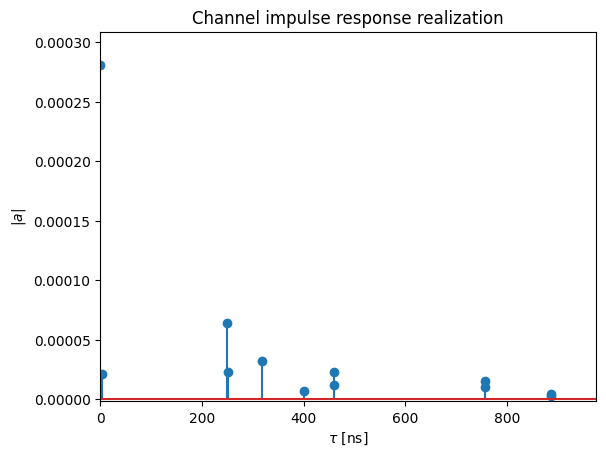

In [17]:
t = tau[0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,0,:,0]
a_max = np.max(a_abs)
# Add dummy entry at start/end for nicer figure
t = np.concatenate([(0.,), t, (np.max(t)*1.1,)])
a_abs = np.concatenate([(np.nan,), a_abs, (np.nan,)])

# And plot the CIR
plt.figure()
plt.title("Channel impulse response realization")

plt.stem(t, a_abs)
plt.xlim([0, np.max(t)])
plt.ylim([-2e-6, a_max*1.1])
plt.xlabel(r"$\tau$ [ns]")
plt.ylabel(r"$|a|$");



In [18]:
# Disable normalization of delays
paths.normalize_delays = False

# Get only the LoS path
_, tau = paths.cir(los=True, reflection=False)
print("Delay of first path without normalization: ", np.squeeze(tau))

paths.normalize_delays = True
_, tau = paths.cir(los=True, reflection=False)
print("Delay of first path with normalization: ", np.squeeze(tau))

Delay of first path without normalization:  2.739189e-07
Delay of first path with normalization:  0.0


In [19]:
# # Compute frequencies of subcarriers and center around carrier frequency
# frequencies = subcarrier_frequencies(fft_size, subcarrier_spacing)

# # Compute the frequency response of the channel at frequencies.
# h_freq = cir_to_ofdm_channel(frequencies,
#                              a,
#                              tau,
#                              normalize=True) # Non-normalized includes path-loss

# # Verify that the channel power is normalized
# h_avg_power = tf.reduce_mean(tf.abs(h_freq)**2).numpy()

# h_freq_plot = tf.abs(h_freq)[0, 0, 0, 0, 0, 0, :]

# print("Shape of h_freq: ", h_freq.shape)
# print("Average power h_freq: ", h_avg_power) # Channel is normalized

5G PUSCH Part

In [20]:
from sionna.nr import PUSCHConfig
class SISOConfig:
    def __init__(self,
                 batch_size=1,
                 num_rx=1,
                 num_tx=1,
                 num_rx_ant=1,
                 num_tx_ant=2,
                 num_time_steps=14,
                 batch_size_cir=100,
                 num_prb=16,
                 mcs_index=14,
                 num_layers=1,
                 mcs_table=2,
                 domain="freq",
                 subcarrier_spacing=15e3,
                 num_symbols=14,
                 num_paths=12,
                 l_min=0):  # Add l_min parameter
        self.batch_size = batch_size
        self.num_rx = num_rx
        self.num_tx = num_tx
        self.num_rx_ant = num_rx_ant
        self.num_tx_ant = num_tx_ant
        self.num_time_steps = num_time_steps
        self.batch_size_cir = batch_size_cir
        self.num_prb = num_prb
        self.mcs_index = mcs_index
        self.num_layers = num_layers
        self.mcs_table = mcs_table
        self.domain = domain
        self.subcarrier_spacing = subcarrier_spacing
        self.num_symbols = num_symbols
        self.num_time_steps = num_symbols
        self.num_paths = num_paths
        self.l_min = l_min  # Store l_min as an attribute
        # Initialize PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_config.carrier.subcarrier_spacing = self.subcarrier_spacing / 1000
        self.pusch_config.carrier.n_size_grid = self.num_prb
        self.pusch_config.num_antenna_ports = self.num_tx_ant
        self.pusch_config.num_layers = self.num_layers
        self.pusch_config.precoding = "non-codebook"
        self.pusch_config.tpmi = 1
        self.pusch_config.dmrs.dmrs_port_set = list(range(self.num_layers))
        self.pusch_config.dmrs.config_type = 1
        self.pusch_config.dmrs.length = 1
        self.pusch_config.dmrs.additional_position = 1
        self.pusch_config.dmrs.num_cdm_groups_without_data = 2
        self.pusch_config.dmrs.positions = [2, 11]  # DMRS at positions 2 and 11
        self.pusch_config.tb.mcs_index = self.mcs_index
        self.pusch_config.tb.mcs_table = self.mcs_table

    def create_pusch_configs(self):
        return [self.pusch_config]  # Only one config for SISO

    # Function for printing the config values
    def print_config(self):
        print(f"Number of PRBs: {self.num_prb}")
        print(f"MCS index: {self.mcs_index}")
        print(f"Number of layers: {self.num_layers}")
        print(f"Number of antennas: {self.num_tx_ant}")
        print(f"Subcarrier spacing: {self.subcarrier_spacing}")
        print(f"Number of transmitters: {self.num_tx}")


class MIMOConfig:
    def __init__(self,
                batch_size=10,
                num_rx=1,
                num_tx=2,
                num_rx_ant=1,
                num_tx_ant=2,
                num_time_steps=14,
                num_prb=16,
                mcs_index=14,
                num_layers=1,
                mcs_table=2,
                domain="freq",
                subcarrier_spacing=15e3,
                num_symbols=14,
                num_paths=12,
                l_min=0):  # Add l_min parameter
        self.num_prb = num_prb
        self.mcs_index = mcs_index
        self.num_layers = num_layers
        self.mcs_table = mcs_table
        self.domain = domain
        self.num_tx_ant = num_tx_ant
        self.num_tx = num_tx
        self.subcarrier_spacing = subcarrier_spacing
        self.num_rx_ant = num_rx_ant
        self.num_rx = num_rx
        self.batch_size = batch_size
        self.num_time_steps = num_symbols
        self.num_paths = num_paths
        self.l_min = l_min  # Store l_min as an attribute
        # Initialize pusch_config here
        self.pusch_config = PUSCHConfig()
        self.pusch_config.carrier.subcarrier_spacing = self.subcarrier_spacing / 1000
        self.pusch_config.carrier.n_size_grid = self.num_prb
        self.pusch_config.num_antenna_ports = self.num_tx_ant
        self.pusch_config.num_layers = self.num_layers
        self.pusch_config.precoding = "codebook"
        self.pusch_config.tpmi = 1
        self.pusch_config.dmrs.dmrs_port_set = list(range(self.num_layers))
        self.pusch_config.dmrs.config_type = 1
        self.pusch_config.dmrs.length = 1
        self.pusch_config.dmrs.additional_position = 1
        self.pusch_config.dmrs.num_cdm_groups_without_data = 2
        self.pusch_config.tb.mcs_index = self.mcs_index
        self.pusch_config.tb.mcs_table = self.mcs_table

    def create_pusch_configs(self):
        pusch_configs = [self.pusch_config]  # Start with the base config
        for i in range(1, self.num_tx):
            pc = self.pusch_config.clone()  # Clone for each transmitter
            pc.dmrs.dmrs_port_set = list(
                range(i * self.num_layers, (i + 1) * self.num_layers))
            pusch_configs.append(pc)
        return pusch_configs

    # Function for printing the config values
    def print_config(self):
        print(f"Number of PRBs: {self.num_prb}")
        print(f"MCS index: {self.mcs_index}")
        print(f"Number of layers: {self.num_layers}")
        print(f"Number of antennas: {self.num_tx_ant}")
        print(f"Subcarrier spacing: {self.subcarrier_spacing}")
        print(f"Number of transmitters: {self.num_tx}")

In [ ]:
# SISO/MIMO/SIMO configs
# from nr_pusch.configs import SISOConfig, MIMOConfig

from sionna.mimo import StreamManagement
from sionna.ofdm import KBestDetector, LinearDetector
from sionna.utils import compute_ber, ebnodb2no
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.channel import OFDMChannel, ApplyOFDMChannel, CIRDataset
from sionna.channel.tr38901 import CDL, TDL
from sionna.channel.tr38901 import AntennaArray, Antenna
import tensorflow as tf
import numpy as np

# Import Sionna RT components


class PUSCHModel(tf.keras.Model):
    def __init__(self, h_freq, ebno_db=2.0, batch_size=100):
        super().__init__()
        self.ebno_db = ebno_db
        self.batch_size = batch_size
        self.h_freq = h_freq  # Store h_freq as attribute
        # Simplified PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_transmitter = PUSCHTransmitter(self.pusch_config)
        self.pusch_receiver = PUSCHReceiver(self.pusch_transmitter)
        self.no = self.compute_noise()
        self.channel = ApplyOFDMChannel(add_awgn=True)

    def compute_noise(self):
        return ebnodb2no(
            self.ebno_db,
            self.pusch_transmitter._num_bits_per_symbol,
            self.pusch_transmitter._target_coderate,
            self.pusch_transmitter.resource_grid,
        )

    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        x, b = self.pusch_transmitter(batch_size)
        y = self.channel([x, self.h_freq, self.no])
        b_hat = self.pusch_receiver([y, self.no])
        return b, b_hat

    def run(self):
        b, b_hat = self.call(self.batch_size, self.ebno_db)
        ber = compute_ber(b, b_hat).numpy()
        print(f"BER: {ber:.5f}")


class PUSCHReceiverExtension:
    def __init__(
        self, config, detector, perfect_csi, transmitter
    ):  # Add transmitter as argument
        self.config = config
        self.perfect_csi = perfect_csi
        rx_tx_association = np.ones([1, config.num_tx], bool)
        stream_management = StreamManagement(rx_tx_association, config.num_layers)

        assert detector in [None, "lmmse", "kbest"], "Unsupported MIMO detector"
        if detector == None:
            self.detector = None
        elif detector == "lmmse":
            self.detector = LinearDetector(
                equalizer="lmmse",
                output="bit",
                demapping_method="maxlog",
                resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                stream_management=stream_management,
                constellation_type="qam",
                num_bits_per_symbol=config.create_pusch_configs()[
                    0
                ].tb.num_bits_per_symbol,
            )
        elif detector == "kbest":
            self.detector = KBestDetector(
                output="bit",
                num_streams=config.num_tx * config.num_layers,
                k=64,
                resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                stream_management=stream_management,
                constellation_type="qam",
                num_bits_per_symbol=config.create_pusch_configs()[
                    0
                ].tb.num_bits_per_symbol,
            )

        if self.perfect_csi:
            self.pusch_receiver = PUSCHReceiver(
                transmitter.pusch_transmitter,  # Use transmitter here
                mimo_detector=self.detector,
                input_domain=config.domain,
                channel_estimator="perfect",
                l_min=config.l_min if config.domain == "time" else None,
            )
        else:
            self.pusch_receiver = PUSCHReceiver(
                transmitter.pusch_transmitter,  # Use transmitter here
                mimo_detector=self.detector,
                input_domain=config.domain,
                l_min=config.l_min if config.domain == "time" else None,
            )


class Channel:
    def __init__(
        self,
        config,
        a,
        tau,
        model_type="",
        scenario="",
        channel_model=None,
    ):
        self.a = a
        self.tau = tau
        resource_grid = PUSCHTransmitterExtension(
            config
        ).pusch_transmitter.resource_grid

        # Check if model_type is valid
        assert model_type.lower() in ["cdl", "tdl", "sionna"], "Invalid model type"
        # self.channel_model = None
        if channel_model is None:
            if model_type.lower() == "cdl":
                carrier_frequency = 2.14e9  # Carrier frequency in Hz.
                # This is needed here to define the antenna element spacing
                # Provide the missing arguments to PanelArray
                num_ut_ant = config.num_tx_ant
                num_bs_ant = config.num_rx_ant
                ut_array = AntennaArray(
                    num_rows=1,
                    num_cols=int(num_ut_ant / 2),
                    polarization="dual",
                    polarization_type="cross",
                    antenna_pattern="38.901",
                    carrier_frequency=carrier_frequency,
                )
                bs_array = AntennaArray(
                    num_rows=1,
                    num_cols=int(num_bs_ant / 2),
                    polarization="dual",
                    polarization_type="cross",
                    antenna_pattern="38.901",
                    carrier_frequency=carrier_frequency,
                )
                # Check if the scenario is valid, if not, setting the default as A with notice
                if scenario.upper() not in ["A", "B", "C", "D", "E"]:
                    print("Invalid scenario, defaulting to A")
                    scenario = "A"
                # Initialize the CDL model with the antenna arrays
                self.channel_model = CDL(
                    model=scenario.upper(),
                    ut_array=ut_array,  # Add ut_array
                    bs_array=bs_array,  # Add bs_array
                    delay_spread=300e-9,
                    carrier_frequency=3.5e9,
                    direction="uplink",
                )
                self.a, self.tau = self.channel_model(
                    batch_size=config.batch_size,
                    num_time_steps=config.num_time_steps,
                    sampling_frequency=config.subcarrier_spacing,
                )
                # print(f"Shape of a: {self.a.shape}")
                # print(f"Shape of tau: {self.tau.shape}")
                # cir_generator = CIRGenerator(self.a, self.tau, config.num_tx, scenario)
                # self.channel_model = CIRDataset(
                #     cir_generator,
                #     config.batch_size,
                #     config.num_rx,
                #     config.num_rx_ant,
                #     config.num_tx,
                #     config.num_tx_ant,
                #     config.num_paths,
                #     config.num_time_steps,
                # )

                # print(f"ChannelModel: {self.channel_model.shape()}")
            elif model_type.lower() == "tdl":
                if scenario.upper() not in ["A", "B", "C", "D", "E"]:
                    print("Invalid scenario, defaulting to A")
                    scenario = "A"

                self.channel_model = TDL(
                    model=scenario.upper(),
                    num_rx_ant=config.num_rx_ant,
                    num_tx_ant=config.num_tx_ant,
                    delay_spread=300e-9,
                    carrier_frequency=3.5e9,
                )
                self.a, self.tau = self.channel_model(
                    batch_size=config.batch_size,
                    num_time_steps=config.num_time_steps,
                    sampling_frequency=config.subcarrier_spacing,
                )
                # cir_generator = CIRGenerator(self.a, self.tau, config.num_tx, scenario)

                # self.channel_model = CIRDataset(
                #     cir_generator,
                #     config.batch_size,
                #     config.num_rx,
                #     config.num_rx_ant,
                #     config.num_tx,
                #     config.num_tx_ant,
                #     config.num_paths,
                #     config.num_time_steps,
                # )

            elif model_type.lower() == "sionna":
                # Init CIR generator
                cir_generator = CIRGenerator(a, tau, config.num_tx, scenario)

                # Initialises a channel model that can be directly used by OFDMChannel layer
                self.channel_model = CIRDataset(
                    cir_generator,
                    config.batch_size,
                    config.num_rx,
                    config.num_rx_ant,
                    config.num_tx,
                    config.num_tx_ant,
                    # 12,
                    config.num_paths,
                    config.num_time_steps,
                )
        else:
            self.channel_model = channel_model
        self._channel = OFDMChannel(
            self.channel_model,
            resource_grid,
            normalize_channel=True,
            return_channel=True,
        )

    def __call__(self, inputs):
        return self._channel(inputs)

    def return_a_tau(self):
        return self.a, self.tau


class CIRGenerator:
    """Creates a generator from a given dataset of channel impulse responses.

    The generator samples ``num_tx`` different transmitters from the given path
    coefficients `a` and path delays `tau` and stacks the CIRs into a single tensor.

    Note that the generator internally samples ``num_tx`` random transmitters
    from the dataset. For this, the inputs ``a`` and ``tau`` must be given for
    a single transmitter (i.e., ``num_tx`` =1) which will then be stacked
    internally.

    Parameters
    ----------
    a : [batch size, num_rx, num_rx_ant, 1, num_tx_ant, num_paths, num_time_steps], complex
        Path coefficients per transmitter.

    tau : [batch size, num_rx, 1, num_paths], float
        Path delays [s] per transmitter.

    num_tx : int
        Number of transmitters

    Output
    -------
    a : [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps], tf.complex
        Path coefficients

    tau : [batch size, num_rx, num_tx, num_paths], tf.float
        Path delays [s]
    """

    def __init__(self, a, tau, num_tx, scenario="siso"):

        # Copy to tensorflow
        self._a = tf.constant(a, tf.complex64)
        self._tau = tf.constant(tau, tf.float32)
        self._dataset_size = self._a.shape[0]

        self._num_tx = num_tx

        self._scenario = scenario

    def __call__(self):

        # Generator implements an infinite loop that yields new random samples
        while True:
            # Sample 4 random users and stack them together
            idx, _, _ = tf.random.uniform_candidate_sampler(
                tf.expand_dims(tf.range(self._dataset_size, dtype=tf.int64), axis=0),
                num_true=self._dataset_size,
                num_sampled=self._num_tx,
                unique=True,
                range_max=self._dataset_size,
            )

            a = tf.gather(self._a, idx)
            tau = tf.gather(self._tau, idx)

            # Transpose to remove batch dimension
            # if self._scenario.lower() == "mimo":
            a = tf.transpose(a, (3, 1, 2, 0, 4, 5, 6))
            tau = tf.transpose(tau, (2, 1, 0, 3))
            # And remove batch-dimension
            a = tf.squeeze(a, axis=0)
            tau = tf.squeeze(tau, axis=0)
            # print(f"Shape of a after going through CIRGenerator: {a.shape}")
            # print(f"Shape of tau after going through CIRGenerator: {tau.shape}")
            yield a, tau


class PUSCHTransmitterExtension:
    def __init__(self, config):
        self.config = config
        self.pusch_transmitter = PUSCHTransmitter(
            config.create_pusch_configs(), output_domain=config.domain
        )


class ChannelModel:
    def __init__(
        self,
        cir_generator,
        batch_size,
        num_rx,
        num_rx_ant,
        num_tx,
        num_tx_ant,
        num_paths,
        num_time_steps,
    ):
        self.cir_generator = cir_generator
        self.batch_size = batch_size
        self.num_rx = num_rx
        self.num_rx_ant = num_rx_ant
        self.num_tx = num_tx
        self.num_tx_ant = num_tx_ant
        self.num_paths = num_paths
        self.num_time_steps = num_time_steps

    # def __call__(self):
    def __call__(self):
        return self.cir_generator()

    def __len__(self):
        return self.batch_size


class Model(tf.keras.Model):
    def __init__(
        self,
        perfect_csi,
        detector,
        config,
        model_type="",
        scenario="",
        a=None,
        tau=None,
        paths=None,
        channel_model=None,
    ):
        super().__init__()
        self.config = config
        self.transmitter = PUSCHTransmitterExtension(self.config)
        self.receiver = PUSCHReceiverExtension(
            self.config, detector, perfect_csi, self.transmitter
        )
        self.a = a
        self.tau = tau
        if channel_model is not None:
            self.channel = Channel(
                self.config,
                self.a,
                self.tau,
                model_type,
                scenario,
                channel_model=channel_model,
            )
        else:
            self.channel = Channel(
                self.config,
                self.a,
                self.tau,
                model_type,
                scenario,
            )
        if a is None:
            # returns a, tau from channel model
            self.a, self.tau = self.channel.return_a_tau()
        self.model_type = model_type
        self.paths = paths

        self.x, self.b = self.transmitter.pusch_transmitter(self.config.batch_size)

    # @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        no = ebnodb2no(
            ebno_db,
            self.transmitter.pusch_transmitter._num_bits_per_symbol,
            self.transmitter.pusch_transmitter._target_coderate,
            self.transmitter.pusch_transmitter.resource_grid,
        )

        y, h = self.channel._channel([self.x, no])

        if self.receiver.perfect_csi:
            b_hat = self.receiver.pusch_receiver([y, h, no])
        else:
            b_hat = self.receiver.pusch_receiver([y, no])
        return self.b, b_hat

    @tf.function(jit_compile=False)
    def run(self, ebno_db):
        b, b_hat = self.call(self.config.batch_size, ebno_db)

        ber = compute_ber(b, b_hat)
        print(ber)
        print(f"BER: {ber.numpy()}")

    # @tf.function(jit_compile=False)
    def extract_features(self, ebno_db):

        self.x, self.b = self.transmitter.pusch_transmitter(self.config.batch_size)
        no = ebnodb2no(
            ebno_db,
            self.transmitter.pusch_transmitter._num_bits_per_symbol,
            self.transmitter.pusch_transmitter._target_coderate,
            self.transmitter.pusch_transmitter.resource_grid,
        )
        y, h = self.channel._channel([self.x, no])
        # Signal Power
        signal_power = tf.reduce_mean(tf.abs(y) ** 2)
        noise_power = tf.reduce_mean(tf.abs(no) ** 2)

        # Highest Power
        highest_power = tf.reduce_max(tf.abs(y) ** 2)

        # Kurtosis
        power = tf.abs(y) ** 2
        mean_power = tf.reduce_mean(power)
        kurtosis = tf.reduce_mean((power - mean_power) ** 4) / (
            tf.reduce_mean((power - mean_power) ** 2) ** 2
        )

        # Skewness
        skewness = tf.reduce_mean((power - mean_power) ** 3) / (
            tf.reduce_mean((power - mean_power) ** 2) ** 1.5
        )

        # CIR realizations
        t = self.tau[0, 0, 0, :] / 1e-9  # Scale to ns
        a_abs = np.abs(self.a)[0, 0, 0, 0, 0, :, 0] # This is beforee the channel model
        print(a_abs.shape) # Shape description: [batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
        print(h.shape)     # Shape description: [batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps]
        print(y.shape)
        plt.figure()
        plt.title("Channel impulse response realization")
        plt.stem(t, a_abs)
        plt.xlabel(r"$\tau$ [ns]")
        plt.ylabel(r"$|a|$")
        plt.show()

        # plt.figure()
        # plt.title("Channel impulse response realization after channel model")
        # plt.stem(t, h_abs)
        # plt.xlabel(r"$\tau$ [ns]")
        # plt.ylabel(r"$|a|$")
        # plt.show()

        if self.model_type.lower() == "sionna":
            power = tf.abs(y) ** 2

            aoa = paths.theta_r
            aod = paths.theta_t
            zod = paths.phi_r
            zoa = paths.phi_t
            toa = self.tau

            # print(toa.shape)
            # print(power.shape)
            # Rising time is the estimation of the time period between the first MPC and the strongest MPC
            first_mpc_time = tf.reduce_min(toa)
            strongest_mpc_time = tf.gather(toa, tf.argmax(power))
            rising_time = strongest_mpc_time - first_mpc_time

            # RMS Delay Spread
            # excess_mean_delay = tf.reduce_sum(toa_broadcasted * power_expanded) / tf.reduce_sum(power_expanded)
            # rms_delay_spread = tf.sqrt(tf.reduce_sum((toa_broadcasted - excess_mean_delay) ** 2 * power_expanded) / tf.reduce_sum(power_expanded))

            # Delay Spread
            mean_delay = tf.reduce_mean(paths.tau)
            delay_spread = tf.sqrt(tf.reduce_mean(tf.square(paths.tau - mean_delay)))

            # # Rician K-factor
            # los_mask = tf.expand_dims(paths.types == Paths.LOS, axis=-1)  # Expand dims to match power shape
            # nlos_mask = tf.expand_dims(~los_mask, axis=-1)  # Expand dims to match power shape
            # print(los_mask.shape)
            # print(nlos_mask.shape)
            # print(power.shape)
            # P_LOS = tf.reduce_sum(tf.abs(self.a) ** 2 * tf.cast(los_mask, tf.float32))
            # P_NLOS = tf.reduce_sum(tf.abs(paths.a) ** 2 * tf.cast(nlos_mask, tf.float32))

            # k_factor = P_LOS / P_NLOS if P_NLOS > 0 else tf.constant(0.0, dtype=tf.float32)
            k_factor = None
            # angular_spread = tf.reduce_mean(tf.abs(paths.a))
            # calculate angular spread based on the formula
            angular_spread = tf.reduce_mean(
                tf.sqrt(
                    (paths.theta_r - tf.reduce_mean(paths.theta_r)) ** 2
                    + (paths.phi_r - tf.reduce_mean(paths.phi_r)) ** 2
                )
            )

            # Mean direction of the Power angular spectrum
            power = tf.reshape(power, [-1])  # Flatten the power tensor if necessary
            theta_r = tf.reshape(
                paths.theta_r, [-1]
            )  # Flatten the theta_r tensor if necessary
            phi_r = tf.reshape(
                paths.phi_r, [-1]
            )  # Flatten the phi_r tensor if necessary

            min_length = min(
                tf.shape(power)[0], tf.shape(theta_r)[0], tf.shape(phi_r)[0]
            )
            power = power[:min_length]
            theta_r = theta_r[:min_length]
            phi_r = phi_r[:min_length]

            mean_theta_real = tf.reduce_sum(tf.cos(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta_imag = tf.reduce_sum(tf.sin(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta = tf.atan2(mean_theta_imag, mean_theta_real)

            mean_phi_real = tf.reduce_sum(tf.cos(phi_r) * power) / tf.reduce_sum(power)
            mean_phi_imag = tf.reduce_sum(tf.sin(phi_r) * power) / tf.reduce_sum(power)
            mean_phi = tf.atan2(mean_phi_imag, mean_phi_real)

            # Angular difference
            # angular_difference = tf.reduce_mean(
            #    tf.abs(tf.exp(1j * paths.theta_t) - tf.exp(1j * paths.theta_r))
            # )
            angular_difference = tf.reduce_mean(
                tf.abs(
                    tf.complex(tf.cos(paths.theta_t), tf.sin(paths.theta_t))
                    - tf.complex(tf.cos(paths.theta_r), tf.sin(paths.theta_r))
                )
            )

            # Ensure the shapes are compatible for matrix multiplication
            theta_r_reshaped = tf.reshape(paths.theta_r, [-1, 1])
            theta_t_reshaped = tf.reshape(paths.theta_t, [-1, 1])
            angular_variant = tf.reduce_sum(
                tf.linalg.eigvals(
                    tf.stack(
                        [
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                        ]
                    )
                )
            )

            doppler_shift = paths.doppler
        elif self.model_type.lower() == "tdl":
            aoa = None  # TDL model does not provide AoA
            aod = None  # TDL model does not provide AoD
            zod = None  # TDL model does not provide ZoD
            zoa = None  # TDL model does not provide ZoA
            toa = self.channel.channel_model.delays
            # Rising time is the estimation of the time period between the first MPC and the strongest MPC
            first_mpc_time = tf.reduce_min(toa)
            strongest_mpc_time = tf.gather(toa, tf.argmax(power))
            rising_time = strongest_mpc_time - first_mpc_time

            # rising_time = tf.reduce_mean(self.channel.channel_model.delays)
            delay_spread = self.channel.channel_model.delay_spread

            # # # RMS Delay Spread
            # excess_mean_delay = tf.reduce_sum(tf.expand_dims(toa, axis=-1) * power) / tf.reduce_sum(power)
            # rms_delay_spread = tf.sqrt(tf.reduce_sum((tf.expand_dims(toa, axis=-1) - excess_mean_delay) ** 2 * power) / tf.reduce_sum(power))

            if self.channel.channel_model.los:
                k_factor = self.channel.channel_model.k_factor
            else:
                k_factor = None

            # Calculate Doppler shift
            batch_size = self.config.batch_size
            v_r = tf.random.uniform(
                shape=[batch_size, 1],
                minval=self.channel.channel_model._min_speed,
                maxval=self.channel.channel_model._max_speed,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_phi = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=2.0 * np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_theta = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            velocities = tf.stack(
                [
                    v_r * tf.cos(v_phi) * tf.sin(v_theta),
                    v_r * tf.sin(v_phi) * tf.sin(v_theta),
                    v_r * tf.cos(v_theta),
                ],
                axis=-1,
            )
            doppler_shift = tf.reduce_mean(tf.abs(velocities))

            # TDL model does not provide angular spread
            angular_spread = None
            mean_theta = None
            mean_phi = None
            angular_difference = None
            angular_variant = None
        elif self.model_type.lower() == "cdl":
            aoa = self.channel.channel_model._aoa
            aod = self.channel.channel_model._aod
            zod = self.channel.channel_model._zod
            zoa = self.channel.channel_model._zoa
            toa = self.channel.channel_model.delays
            # Rising time is the estimation of the time period between the first MPC and the strongest MPC
            first_mpc_time = tf.reduce_min(toa)
            strongest_mpc_time = tf.gather(toa, tf.argmax(power))
            rising_time = strongest_mpc_time - first_mpc_time

            # # # RMS Delay Spread
            # excess_mean_delay = tf.reduce_sum(tf.expand_dims(toa, axis=-1) * power) / tf.reduce_sum(power)
            # rms_delay_spread = tf.sqrt(tf.reduce_sum((tf.expand_dims(toa, axis=-1) - excess_mean_delay) ** 2 * power) / tf.reduce_sum(power))

            # Delay Spread
            delay_spread = self.channel.channel_model.delay_spread

            if self.channel.channel_model.los:
                k_factor = self.channel.channel_model.k_factor
            else:
                k_factor = None

            angular_spread = (
                tf.reduce_mean(aoa)
                + tf.reduce_mean(aod)
                + tf.reduce_mean(zod)
                + tf.reduce_mean(zoa)
            ) / 4

            # Angular difference
            angular_difference = tf.reduce_mean(
                tf.abs(
                    tf.complex(tf.cos(paths.theta_t), tf.sin(paths.theta_t))
                    - tf.complex(tf.cos(paths.theta_r), tf.sin(paths.theta_r))
                )
            )

            # Mean direction of the Power angular spectrum
            power = tf.reshape(power, [-1])  # Flatten the power tensor if necessary
            theta_r = tf.reshape(
                paths.theta_r, [-1]
            )  # Flatten the theta_r tensor if necessary
            phi_r = tf.reshape(
                paths.phi_r, [-1]
            )  # Flatten the phi_r tensor if necessary

            min_length = min(
                tf.shape(power)[0], tf.shape(theta_r)[0], tf.shape(phi_r)[0]
            )
            power = power[:min_length]
            theta_r = theta_r[:min_length]
            phi_r = phi_r[:min_length]

            mean_theta_real = tf.reduce_sum(tf.cos(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta_imag = tf.reduce_sum(tf.sin(theta_r) * power) / tf.reduce_sum(
                power
            )
            mean_theta = tf.atan2(mean_theta_imag, mean_theta_real)

            mean_phi_real = tf.reduce_sum(tf.cos(phi_r) * power) / tf.reduce_sum(power)
            mean_phi_imag = tf.reduce_sum(tf.sin(phi_r) * power) / tf.reduce_sum(power)
            mean_phi = tf.atan2(mean_phi_imag, mean_phi_real)

            angular_difference = tf.reduce_mean(
                tf.abs(
                    tf.complex(tf.cos(paths.theta_t), tf.sin(paths.theta_t))
                    - tf.complex(tf.cos(paths.theta_r), tf.sin(paths.theta_r))
                )
            )

            # Ensure the shapes are compatible for matrix multiplication
            theta_r_reshaped = tf.reshape(paths.theta_r, [-1, 1])
            theta_t_reshaped = tf.reshape(paths.theta_t, [-1, 1])
            angular_variant = tf.reduce_sum(
                tf.linalg.eigvals(
                    tf.stack(
                        [
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_r_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_r_reshaped,
                                    transpose_a=True,
                                )
                            ),
                            tf.math.real(
                                tf.linalg.matmul(
                                    tf.math.conj(theta_t_reshaped),
                                    theta_t_reshaped,
                                    transpose_a=True,
                                )
                            ),
                        ]
                    )
                )
            )

            batch_size = self.config.batch_size
            v_r = tf.random.uniform(
                shape=[batch_size, 1],
                minval=self.channel.channel_model._min_speed,
                maxval=self.channel.channel_model._max_speed,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_phi = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=2.0 * np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            v_theta = tf.random.uniform(
                shape=[batch_size, 1],
                minval=0.0,
                maxval=np.pi,
                dtype=self.channel.channel_model._real_dtype,
            )
            velocities = tf.stack(
                [
                    v_r * tf.cos(v_phi) * tf.sin(v_theta),
                    v_r * tf.sin(v_phi) * tf.sin(v_theta),
                    v_r * tf.cos(v_theta),
                ],
                axis=-1,
            )
            doppler_shift = tf.reduce_mean(tf.abs(velocities))
        features = {
            "a_abs": safe_numpy(a_abs),
            "t": safe_numpy(t),
            "snr": safe_numpy(
                10 * tf.math.log(signal_power / noise_power) / tf.math.log(10.0)
            ),
            "highest_received_power": safe_numpy(highest_power),
            "kurtosis": safe_numpy(kurtosis),
            "skewness": safe_numpy(skewness),
            "mean": safe_numpy(tf.reduce_mean(y)),
            "std": safe_numpy(tf.math.reduce_std(y)),
            "aoa": safe_numpy(aoa) if aoa is not None else aoa,
            "aod": safe_numpy(aod) if aod is not None else aod,
            "zoa": safe_numpy(zoa) if zoa is not None else zoa,
            "zod": safe_numpy(zod) if zod is not None else zod,
            "toa_prs": safe_numpy(toa),
            "rising_time": safe_numpy(rising_time),
            "delay_spread": safe_numpy(delay_spread),
            # "rms_delay_spread": safe_numpy(rms_delay_spread),
            "rician_k_factor": safe_numpy(k_factor),
            "angular_spread": (
                safe_numpy(angular_spread)
                if angular_spread is not None
                else angular_spread
            ),
            "mean_theta": (
                safe_numpy(mean_theta) if mean_theta is not None else mean_theta
            ),
            "mean_phi": safe_numpy(mean_phi) if mean_phi is not None else mean_phi,
            "angular_difference": (
                safe_numpy(angular_difference)
                if angular_difference is not None
                else angular_difference
            ),
            "angular_variant": (
                safe_numpy(angular_variant)
                if angular_variant is not None
                else angular_variant
            ),
            "doppler_shift": safe_numpy(doppler_shift),
            "normalized_delay_power_correlation": safe_numpy(
                self.compute_normalized_delay_power_correlation(y, h)
            ),
        }
        return features

    # @tf.function(jit_compile=False)
    def compute_normalized_delay_power_correlation(self, y, h):
        if self.model_type.lower() in ["cdl", "tdl"]:
            # For CDL and TDL models, use the channel model directly
            # print("Model type is CDL/TDL")
            # print(y.shape)
            # print(h.shape)
            y_tiled = tf.reshape(y, [-1])
            h_tiled = tf.reshape(h, [-1])
            # print(y_tiled.shape)
            # print(h_tiled.shape)
            # Ensure the shapes are compatible for broadcasting
            if y_tiled.shape[0] < h_tiled.shape[0]:
                h_tiled = h_tiled[: y_tiled.shape[0]]
            elif y_tiled.shape[0] > h_tiled.shape[0]:
                y_tiled = y_tiled[: h_tiled.shape[0]]
            correlation = tf.reduce_mean(y_tiled * tf.math.conj(h_tiled))
            return correlation.numpy()

        # For Sionna model
        # print("Model type is not CDL/TDL")
        y_expanded = y
        y_tiled = y_expanded
        # Check if SISO or MIMO to expand
        if self.config.num_tx != 1 or self.config.num_tx_ant != 1:
            if self.config.num_tx != 1:
                y_expanded = tf.expand_dims(y, axis=self.config.num_tx - 1)
            if self.config.num_tx_ant != 1:
                y_expanded = tf.expand_dims(y_expanded, axis=self.config.num_tx_ant)
                y_tiled = tf.tile(
                    y_expanded,
                    [1, 1, 1, self.config.num_tx, self.config.num_tx_ant, 1, 1],
                )
        else:
            y_tiled = y

        y_tiled = tf.reshape(y_tiled, [-1])
        h_tiled = tf.reshape(h, [-1])

        # Ensure the shapes are compatible for broadcasting
        if y_tiled.shape[0] < h_tiled.shape[0]:
            h_tiled = h_tiled[: y_tiled.shape[0]]
        elif y_tiled.shape[0] > h_tiled.shape[0]:
            y_tiled = y_tiled[: h_tiled.shape[0]]

        # Print shapes for debugging
        # print(f"Shape of y_tiled: {y_tiled.shape}")
        # print(f"Shape of h_tiled: {h_tiled.shape}")

        correlation = tf.reduce_mean(y_tiled * tf.math.conj(h_tiled))

        return correlation.numpy()

    def plot_cir_realization(self, a, tau):
        t = tau[0, 0, 0, :] / 1e-9  # Scale to ns
        a_abs = np.abs(a)[0, 0, 0, 0, 0, :, 0]
        a_max = np.max(a_abs)
        # Add dummy entry at start/end for nicer figure
        t = np.concatenate([(0.0,), t, (np.max(t) * 1.1,)])
        a_abs = np.concatenate([(np.nan,), a_abs, (np.nan,)])


def safe_numpy(tensor):
    try:
        return tensor.numpy()
    except:
        return tensor

SISO Configuration Test

In [22]:
# model = PUSCHModel(h_freq, batch_size=100)
# model.run()

siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=2,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14
)
paths = scene.compute_paths(max_depth=5, num_samples=5e4, los=True)

paths.apply_doppler(sampling_frequency=siso_configuration.subcarrier_spacing,
                    num_time_steps=siso_configuration.num_time_steps,
                    # We can set additional tx speeds
                    tx_velocities=[3., 0, 0],
                    rx_velocities=[0, 7., 0])  # Or rx speeds




Generating sample 1/1 for Eb/No value 5.239882614641974
(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


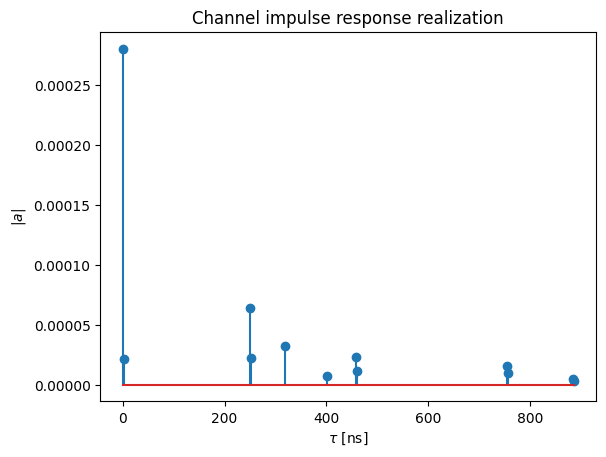

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


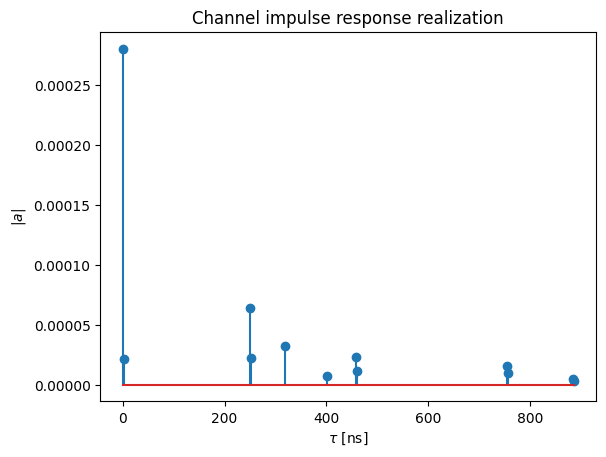

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


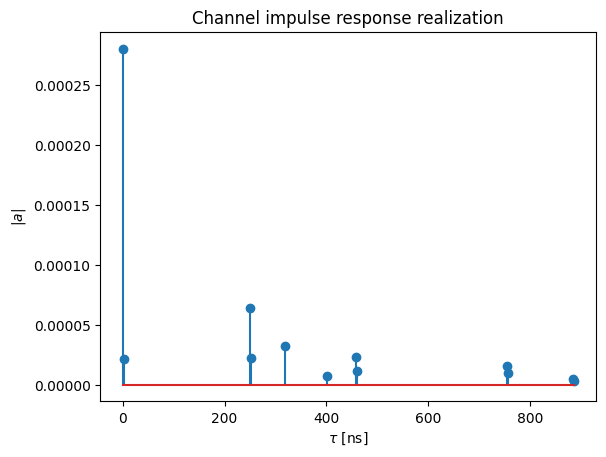

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


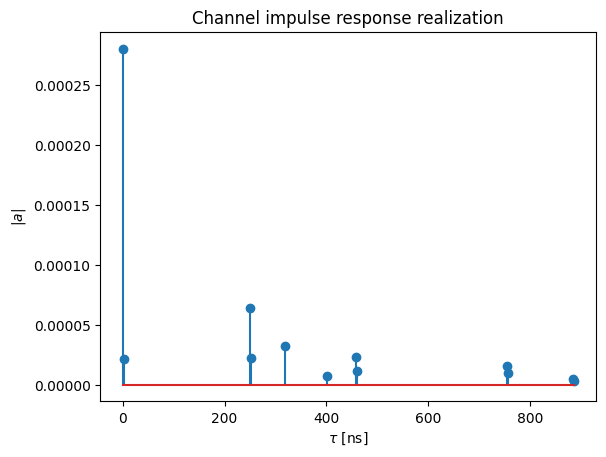

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


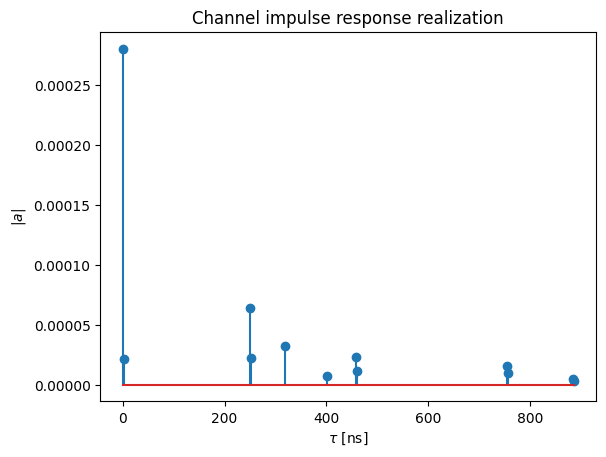

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


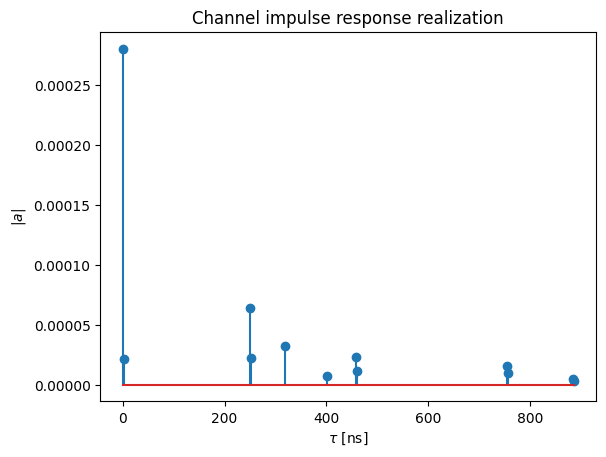

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


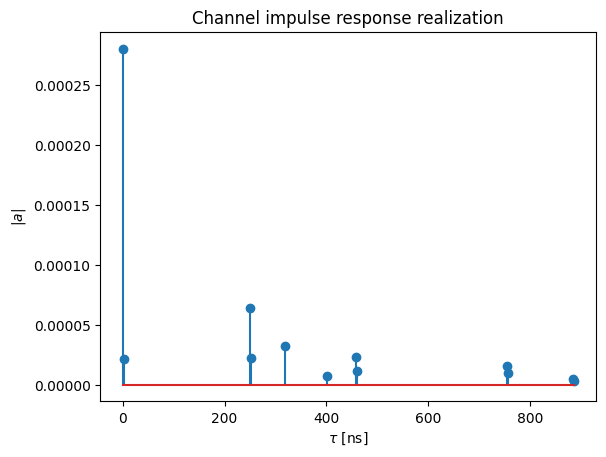

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


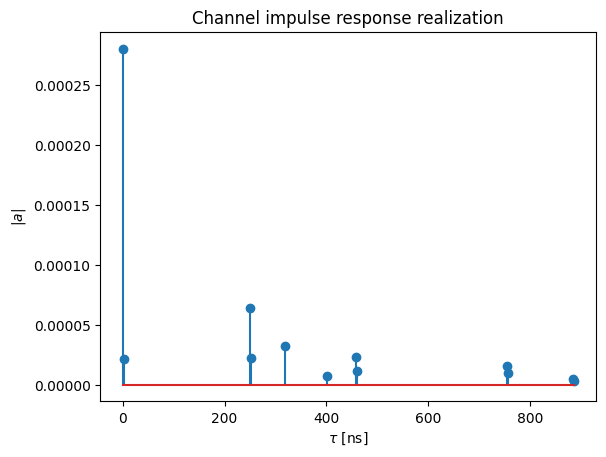

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


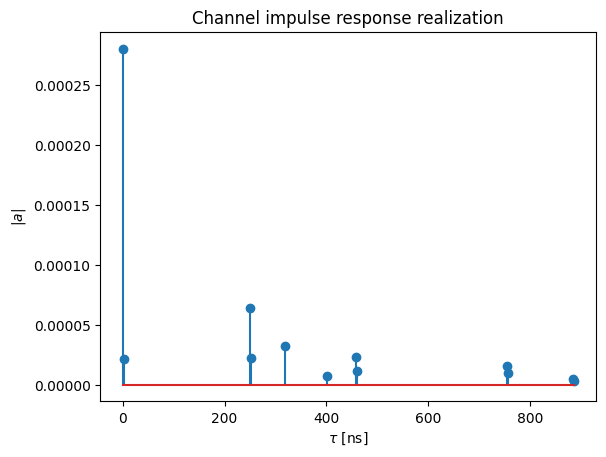

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


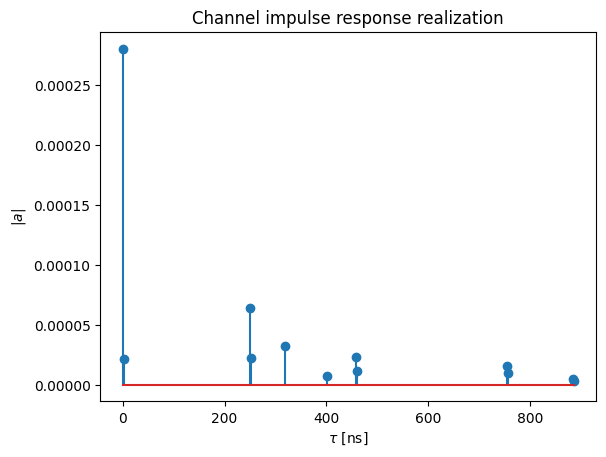

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


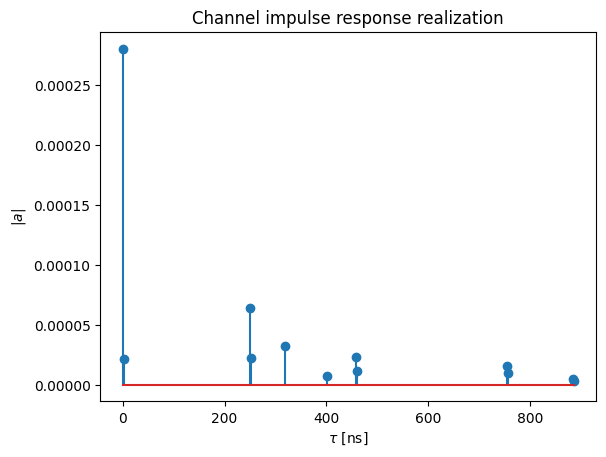

(12,)
(1, 1, 2, 1, 1, 14, 192)
(1, 1, 2, 14, 192)


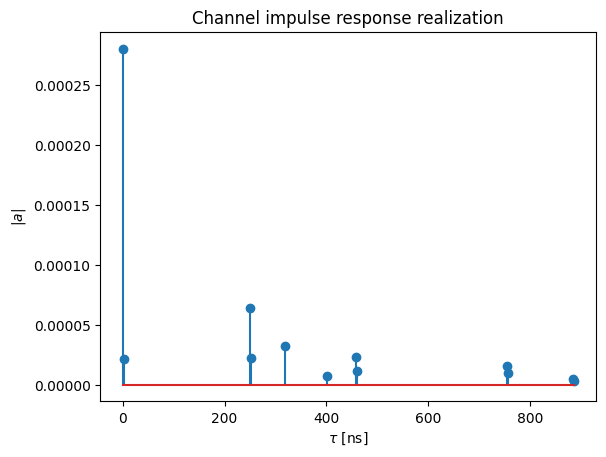

In [24]:
# features = {}
# for ebno_db in range(-3, 19, 2):
#     features_extracted = model.extract_features(ebno_db=ebno_db)
#     features[f"sionna_siso_{ebno_db}"] = features_extracted
# Define the number of samples per Eb/No value

# Initialize the dataset
dataset = []

num_samples_per_scenario = 1

ebno_min = -3
ebno_max = 19
a, tau = paths.cir()       
# Create the model
model = Model(
    a=a, tau=tau,
    perfect_csi=True,
    detector=None,
    config=siso_configuration,
    model_type="sionna",
    scenario="siso",
    paths=paths
)
# Loop through the number of samples per Eb/No value
for sample_idx in range(num_samples_per_scenario):
    ebno_db = np.random.uniform(ebno_min, ebno_max)
    print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for Eb/No value {ebno_db}")

    # Extract features for each path separately
    for path_idx in range(paths.a.shape[-2]):
        # Extract features for the current path

        features_extracted = model.extract_features(ebno_db=ebno_db)


        # Determine if the current path is LOS or NLOS
        path_type = paths.types[0, path_idx].numpy()
        if path_type == Paths.LOS:
            label = "los"
        else:
            label = "nlos"
        # print(f"Paths inside loop: {paths.a.shape[-2]}, label: {label}")
        # Add additional metadata
        features_extracted["scenario"] = "siso"
        features_extracted["model_type"] = "sionna"
        features_extracted["ebno_db"] = ebno_db
        features_extracted["label"] = label

        # Append the features to the dataset (Aggregation)
        dataset.append(features_extracted)

In [ ]:
# max_depths = 10 # evaluate performance up to 10 reflections
# depths = range(1,max_depths+1)
# ts = []
# pl_avg = []
# for d in depths:
#     # save start time
#     t = time.time()
#     # run the ray tracer
#     paths = scene.compute_paths(max_depth=d)
#     # and measure the required time interval
#     ts.append(time.time()-t)
# # and plot results
# plt.figure()
# plt.plot(depths, ts, color="b");
# plt.xlabel("Max. depth")
# plt.ylabel("Runtime (s)", color="b")
# plt.grid(which="both")
# plt.xlim([1, max_depths]);

In [ ]:
# t = time.time()
# paths = scene.compute_paths(max_depth=3, diffraction=False)
# print("Time without diffraction and scattering:" , time.time()-t)

# t = time.time()
# paths = scene.compute_paths(max_depth=3, diffraction=True)
# print("Time with diffraction:" , time.time()-t)

# t = time.time()
# paths = scene.compute_paths(max_depth=3, scattering=True)
# print("Time with scattering:" , time.time()-t)

RECLEAN THE SCENE

In [ ]:
# Remove old transmitter and add new one
scene.remove("tx")

tx = Transmitter(name="tx",
                 position=[-210,73,105], # top of Frauenkirche
                 orientation=[0,0,0])
scene.add(tx)

# We could have alternatively modified the properties position and orientation of the existing transmitter
#scene.get("tx").position = [-210,73,105]
#scene.get("tx").orientation = [0,0,0]

In [ ]:
 # Open 3D preview (only works in Jupyter notebook)
if no_preview:
    scene.render(camera="scene-cam-0", num_samples=512, resolution=resolution);

In [ ]:
# %%skip_if no_preview
# scene.preview()

In [ ]:
cm = scene.coverage_map(max_depth=5,
                        diffraction=True, # Disable to see the effects of diffraction
                        cm_cell_size=(5., 5.), # Grid size of coverage map cells in m
                        combining_vec=None,
                        precoding_vec=None,
                        num_samples=int(5e4)) # Reduce if your hardware does not have enough memory

In [ ]:
# Create new camera
tx_pos = scene.transmitters["tx"].position.numpy()
bird_pos = tx_pos.copy()
bird_pos[-1] = 1000 # Set height of coverage map to 1000m above tx
bird_pos[-2]-= 0.01 # Slightly move the camera for correct orientation

# Create new camera
bird_cam = Camera("birds_view", position=bird_pos, look_at=tx_pos)

scene.add(bird_cam)

if no_preview:
    scene.render(camera="birds_view", coverage_map=cm, num_samples=512, resolution=resolution);

In [ ]:
# %%skip_if no_preview
# scene.preview(coverage_map=cm)

In [ ]:
cm.show(tx=0); # If multiple transmitters exist, tx selects for which transmitter the cm is shown


MIMO Configuration

In [ ]:
# System parameters
subcarrier_spacing = 30e3
num_time_steps = 14 # Total number of ofdm symbols per slot

num_tx = 4 # Number of users
num_rx = 1 # Only one receiver considered
num_tx_ant = 4 # Each user has 4 antennas
num_rx_ant = 16 # The receiver is equipped with 16 antennas

# batch_size for CIR generation
batch_size_cir = 500


In [ ]:
# Remove old tx from scene
scene.remove("tx")

scene.synthetic_array = True # Emulate multiple antennas to reduce ray tracing complexity

# Transmitter (=basestation) has an antenna pattern from 3GPP 38.901
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=int(num_rx_ant/2), # We want to transmitter to be equiped with the 16 rx antennas
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="cross")

# Create transmitter
tx = Transmitter(name="tx",
                 position=[8.5,21,27],
                 look_at=[45,90,1.5]) # optional, defines view direction
scene.add(tx)
max_depth = 5 # Defines max number of ray interactions
del cm
# Update coverage_map
cm = scene.coverage_map(max_depth=max_depth,
                        diffraction=True,
                        cm_cell_size=(1., 1.),
                        combining_vec=None,
                        precoding_vec=None,
                        num_samples=int(5e4))

In [ ]:
min_gain_db = -130 # in dB; ignore any position with less than -130 dB path gain
max_gain_db = 0 # in dB; ignore strong paths

# sample points in a 5-400m radius around the receiver
min_dist = 5 # in m
max_dist = 400 # in m

#sample batch_size random user positions from coverage map
ue_pos, _ = cm.sample_positions(num_pos=batch_size_cir,
                                metric="path_gain",
                                min_val_db=min_gain_db,
                                max_val_db=max_gain_db,
                                min_dist=min_dist,
                                max_dist=max_dist)
ue_pos = tf.squeeze(ue_pos)

In [ ]:
# Remove old receivers from scene
scene.remove("rx")
for i in range(batch_size_cir):
    scene.remove(f"rx-{i}")

# Configure antenna array for all receivers (=UEs)
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=int(num_tx_ant/2), # Each receiver is equipped with 4 tx antennas (uplink)
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso", # UE orientation is random
                             polarization="cross")

# Create batch_size receivers
for i in range(batch_size_cir):
    rx = Receiver(name=f"rx-{i}",
                  position=ue_pos[i], # Random position sampled from coverage map
                  )
    scene.add(rx)

# And visualize the scene
if no_preview:
    scene.render("birds_view", show_devices=True, resolution=resolution);

In [ ]:
# %%skip_if no_preview
# scene.preview(show_devices=True, coverage_map=cm)

In [ ]:
target_num_cirs = 2500 # Defines how many different CIRS are generated.
# Remark: some path are removed if no path was found for this position

max_depth = 5
min_gain_db = -130 # in dB / ignore any position with less than -130 dB path gain
max_gain_db = 0 # in dB / ignore any position with more than 0 dB path gain

# Sample points within a 10-400m radius around the transmitter
min_dist = 10 # in m
max_dist = 400 # in m

# Placeholder to gather channel impulse reponses
a = None
tau = None

# Each simulation returns batch_size_cir results
num_runs = int(np.ceil(target_num_cirs/batch_size_cir))
for idx in range(num_runs):
    print(f"Progress: {idx+1}/{num_runs}", end="\r")

    # Sample random user positions
    ue_pos, _ = cm.sample_positions(
                        num_pos=batch_size_cir,
                        metric="path_gain",
                        min_val_db=min_gain_db,
                        max_val_db=max_gain_db,
                        min_dist=min_dist,
                        max_dist=max_dist)
    ue_pos = tf.squeeze(ue_pos)

    # Update all receiver positions
    for idx in range(batch_size_cir):
        scene.receivers[f"rx-{idx}"].position = ue_pos[idx]

    # Simulate CIR
    paths = scene.compute_paths(
                    max_depth=max_depth,
                    # diffraction=True,
                    los=True,
                    num_samples=5e4) # shared between all tx in a scene

    # Transform paths into channel impulse responses
    paths.reverse_direction = True # Convert to uplink direction
    paths.apply_doppler(sampling_frequency=subcarrier_spacing,
                        num_time_steps=14,
                        tx_velocities=[0.,0.,0],
                        rx_velocities=[3.,3.,0])

    # We fix here the maximum number of paths to 75 which ensures
    # that we can simply concatenate different channel impulse reponses
    a_, tau_ = paths.cir(num_paths=12)
    # del paths # Free memory

    if a is None:
        a = a_.numpy()
        tau = tau_.numpy()
    else:
        # Concatenate along the num_tx dimension
        a = np.concatenate([a, a_], axis=3)
        tau = np.concatenate([tau, tau_], axis=2)

# del cm # Free memory

# Exchange the num_tx and batchsize dimensions
a = np.transpose(a, [3, 1, 2, 0, 4, 5, 6])
tau = np.transpose(tau, [2, 1, 0, 3])

# Remove CIRs that have no active link (i.e., a is all-zero)
p_link = np.sum(np.abs(a)**2, axis=(1,2,3,4,5,6))
a = a[p_link>0.,...]
tau = tau[p_link>0.,...]

print("Shape of a:", a.shape)
print("Shape of tau: ", tau.shape)

In [ ]:
# features = {}
# for ebno_db in range(-3, 19, 2):
#     features_extracted = model.extract_features(ebno_db=ebno_db)
#     features[f"sionna_siso_{ebno_db}"] = features_extracted
# Define the number of samples per Eb/No value

# Initialize the dataset
dataset = []

num_samples_per_scenario = 1

ebno_min = -3
ebno_max = 19
a, tau = paths.cir()       
# Create the model
model = Model(
    a=a, tau=tau,
    perfect_csi=False,
    detector=None,
    config=siso_configuration,
    model_type="sionna",
    scenario="siso",
    paths=paths
)
# Loop through the number of samples per Eb/No value
# for sample_idx in range(num_samples_per_scenario):
#     # while True:
#     #     try: 
#             ebno_db = np.random.uniform(ebno_min, ebno_max)
#             print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for Eb/No value {ebno_db}")

#             # Extract features (Simulation)


            
#             features_extracted = model.extract_features(ebno_db=ebno_db)

#             # Add additional metadata
#             features_extracted["scenario"] = "siso"
#             features_extracted["model_type"] = "sionna"
#             features_extracted["ebno_db"] = ebno_db
#             features_extracted["label"] = "los"
#             # Append the features to the dataset (Aggregation)
#             dataset.append(features_extracted)

#         #     break
#         # except Exception as e:
#         #     print(f"Error occurred: {e}. Retrying sample {sample_idx + 1}/{num_samples_per_scenario}...")
#         #     del a, tau
#         #     a, tau = paths.cir(los=True)
#         #     # Create the model
#         #     model = Model(
#         #         a=a, tau=tau,
#         #         perfect_csi=False,
#         #         detector=None,
#         #         config=siso_configuration,
#         #         model_type="sionna",
#         #         scenario="siso",
#         #         paths=paths
#         #     )

# Loop through the number of samples per Eb/No value
for sample_idx in range(num_samples_per_scenario):
    ebno_db = np.random.uniform(ebno_min, ebno_max)
    print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for Eb/No value {ebno_db}")

    # Extract features for each path separately
    for path_idx in range(paths.a.shape[-2]):
        # Extract features for the current path

        features_extracted = model.extract_features(ebno_db=ebno_db, path_idx=path_idx)


        # Determine if the current path is LOS or NLOS
        path_type = paths.types[0, path_idx].numpy()
        if path_type == Paths.LOS:
            label = "los"
        else:
            label = "nlos"
        # print(f"Paths inside loop: {paths.a.shape[-2]}, label: {label}")
        # Add additional metadata
        features_extracted["scenario"] = "siso"
        features_extracted["model_type"] = "sionna"
        features_extracted["ebno_db"] = ebno_db
        features_extracted["label"] = label

        # Append the features to the dataset (Aggregation)
        dataset.append(features_extracted)

In [ ]:
batch_size = 10 # Must be the same for the BER simulations as CIRDataset returns fixed batch_size

mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=num_tx_ant,
    num_tx=num_tx,
    subcarrier_spacing=subcarrier_spacing,
    num_rx_ant=num_rx_ant,
    num_rx=num_rx,
    num_symbols=num_time_steps,
    batch_size=batch_size,
    num_paths=12
)


In [ ]:
# for ebno_db in range(-3, 19, 2):
#     features_extracted = model.extract_features(ebno_db=ebno_db)
#     features[f"sionna_mimo_{ebno_db}"] = features_extracted


num_samples_per_scenario = 200
ebno_min = -3
# ebno_max = 19
ebno_max = 20
# Create the model
batch_size = 20 # Must be the same for the BER simulations as CIRDataset returns fixed batch_size

# model = Model(a=a, tau=tau,
#               perfect_csi=False,
#               detector=None,
#               config=mimo_configuration,
#               model_type="sionna",
#               scenario="mimo",
#               #   paths=paths
#               )
# model.run(10)
cir_generator = CIRGenerator(a,
                             tau,
                             num_tx)
# Initialises a channel model that can be directly used by OFDMChannel layer
channel_model = CIRDataset(cir_generator,
                           batch_size,
                           num_rx,
                           num_rx_ant,
                           num_tx,
                           num_tx_ant,
                           75,
                           num_time_steps)



In [ ]:
model = Model(perfect_csi=False,
                detector=None,
                config=mimo_configuration,
                model_type="sionna",
                scenario="mimo",
                a=a,
                tau=tau,
                paths=paths)
                # channel_model=channel_model)


# Loop through the number of samples per Eb/No value
for sample_idx in range(num_samples_per_scenario):
    ebno_db = np.random.uniform(ebno_min, ebno_max)
    print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for Eb/No value {ebno_db}")

    # Extract features for each path separately
    for path_idx in range(paths.a.shape[-2]):
        # while True
            # try:
                # Extract features for the current path
                features_extracted = model.extract_features(ebno_db=ebno_db)

                # Determine if the current path is LOS or NLOS
                path_type = paths.types[0, path_idx].numpy()
                if path_type == Paths.LOS:
                    label = "los"
                else:
                    label = "nlos"

                # Add additional metadata
                features_extracted["scenario"] = "mimo"
                features_extracted["model_type"] = "sionna"
                features_extracted["ebno_db"] = ebno_db
                features_extracted["label"] = label

                # Append the features to the dataset (Aggregation)
                dataset.append(features_extracted)
                # break
            # except Exception as e:
            #     print(f"Error occurred: {e}. Retrying sample {sample_idx + 1}/{num_samples_per_scenario}...")
            #     del model
            #     if patience > 3:
            #         # Placeholder to gather channel impulse responses
            #         a = None
            #         tau = None

            #         # Each simulation returns batch_size_cir results
            #         num_runs = int(np.ceil(target_num_cirs / batch_size_cir))
            #         for idx in range(num_runs):
            #             print(f"Progress: {idx + 1}/{num_runs}", end="\r")

            #             # Sample random user positions
            #             ue_pos, _ = cm.sample_positions(
            #                 num_pos=batch_size_cir,
            #                 metric="path_gain",
            #                 min_val_db=min_gain_db,
            #                 max_val_db=max_gain_db,
            #                 min_dist=min_dist,
            #                 max_dist=max_dist)
            #             ue_pos = tf.squeeze(ue_pos)

            #             # Update all receiver positions
            #             for idx in range(batch_size_cir):
            #                 scene.receivers[f"rx-{idx}"].position = ue_pos[idx]

            #             # Simulate CIR
            #             paths = scene.compute_paths(
            #                 max_depth=max_depth,
            #                 num_samples=5e4)  # shared between all tx in a scene

            #             # Transform paths into channel impulse responses
            #             paths.reverse_direction = True  # Convert to uplink direction
            #             paths.apply_doppler(sampling_frequency=subcarrier_spacing,
            #                                 num_time_steps=14,
            #                                 tx_velocities=[0., 0., 0],
            #                                 rx_velocities=[3., 3., 0])

            #             # We fix here the maximum number of paths to 75 which ensures
            #             # that we can simply concatenate different channel impulse responses
            #             a_, tau_ = paths.cir(num_paths=75, los=True)

            #             if a is None:
            #                 a = a_.numpy()
            #                 tau = tau_.numpy()
            #             else:
            #                 # Concatenate along the num_tx dimension
            #                 a = np.concatenate([a, a_], axis=3)
            #                 tau = np.concatenate([tau, tau_], axis=2)

            #         # Exchange the num_tx and batchsize dimensions
            #         a = np.transpose(a, [3, 1, 2, 0, 4, 5, 6])
            #         tau = np.transpose(tau, [2, 1, 0, 3])

            #         # Remove CIRs that have no active link (i.e., a is all-zero)
            #         p_link = np.sum(np.abs(a) ** 2, axis=(1, 2, 3, 4, 5, 6))
            #         a = a[p_link > 0., ...]
            #         tau = tau[p_link > 0., ...]

            #         patience = 0

            #         # delete from the memory old cir_generator and channel_model for memory management
            #         del cir_generator
            #         del channel_model
            #         cir_generator = CIRGenerator(a,
            #                                      tau,
            #                                      num_tx)
            #         # Initialises a channel model that can be directly used by OFDMChannel layer
            #         channel_model = CIRDataset(cir_generator,
            #                                    batch_size,
            #                                    num_rx,
            #                                    num_rx_ant,
            #                                    num_tx,
            #                                    num_tx_ant,
            #                                    75,
            #                                    num_time_steps)

            #     model = Model(perfect_csi=False,
            #                   detector=None,
            #                   config=siso_configuration,
            #                   model_type="mimo",
            #                   scenario="mimo",
            #                   a=a,
            #                   tau=tau,
            #                   channel_model=channel_model)
            #     patience += 1

CDL and TDL Configuration

In [ ]:
# Define the number of samples per scenario and model type
num_samples_per_scenario = 2

# Initialize the dataset



# Define the scenarios and Eb/No values
scenarios = ["A", "B", "C", "D", "E"]
ebno_min = -3
ebno_max = 19
# model_types = ["tdl", "cdl"]
# make only cdl for debugging
model_types = ["tdl","cdl"]


# System parameters
subcarrier_spacing = 30e3
num_time_steps = 14 # Total number of ofdm symbols per slot

num_tx = 4 # Number of users
num_rx = 1 # Only one receiver considered
num_tx_ant = 4 # Each user has 4 antennas
num_rx_ant = 16 # The receiver is equipped with 16 antennas

# batch_size for CIR generation
batch_size_cir = 500
batch_size = 10 # Must be the same for the BER simulations as CIRDataset returns fixed batch_size
mimo_configuration = MIMOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=1,
    domain="freq",
    num_tx_ant=num_tx_ant,
    num_tx=num_tx,
    subcarrier_spacing=subcarrier_spacing,
    num_rx_ant=num_rx_ant,
    num_rx=num_rx,
    num_symbols=num_time_steps,
    batch_size=batch_size,
    num_paths=23
)
siso_configuration = SISOConfig(
    batch_size=1,
    num_rx=1,
    num_rx_ant=2,
    num_tx=1,
    num_tx_ant=1,
    subcarrier_spacing=15e3,
    num_time_steps=14,
    num_paths=23
)
# Loop through each model type
for model_type in model_types:
    # Loop through each scenario
    for scenario in scenarios:
        if model_type == "tdl":
            model = Model(
                perfect_csi=False,
                detector=None,
                config=siso_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        else:
            model = Model(
                perfect_csi=False,
                detector=None,
                config=mimo_configuration,
                model_type=model_type,
                scenario=scenario,
            )
        # Loop through the number of samples per scenario
        for sample_idx in range(num_samples_per_scenario):
            ebno_db = np.random.uniform(ebno_min, ebno_max)
            print(f"Generating sample {sample_idx + 1}/{num_samples_per_scenario} for scenario {scenario} and model type {model_type}")

            # Randomly select an Eb/No value (Monte Carlo sampling)

            # Extract features (Simulation)
            features = model.extract_features(ebno_db=ebno_db)

            # Add additional metadata
            features["scenario"] = scenario
            features["ebno_db"] = ebno_db
            features["model_type"] = model_type
            if scenario == "A" or scenario == "B" or scenario == "C":
                features["label"] = "nlos"
            else:
                features["label"] = "los"
            # Append the features to the dataset (Aggregation)
            dataset.append(features)

In [ ]:
# Convert the dataset to a structured format (e.g., Pandas DataFrame)
df = pd.DataFrame(dataset)

# Save the dataset to a file (e.g., CSV)
df.to_csv("dataset.csv", index=False)

# Convert to HDF5
df.to_hdf("dataset.h5", key="data", mode='w')

print("Dataset generation complete. Saved to dataset.csv and dataset.h5")